# 🎮 Sesión 2: Extracción de Grafos (Caso Twitch)
De datos tabulares a topología de red.

## 🧠 Teoría Fundamental: De la Tabla a la Red
En el mundo real, los grafos rara vez vienen estructurados. Se **extraen** de bases de datos relacionales o logs transaccionales mediante ingeniería de datos.

### 1. El Grafo Bipartito
Es una red donde los nodos se dividen en dos conjuntos disjuntos (Ej. `Usuarios` y `Películas`, o `Clientes` y `Productos`). Las conexiones solo pueden existir **cruzando** de un conjunto a otro. Dos usuarios no pueden conectarse entre sí directamente.

### 2. Grafos de Co-ocurrencia (Colapsando la Red)
Para encontrar relaciones entre elementos del mismo conjunto (Ej. qué tan similares son dos usuarios, o qué productos se compran juntos), "colapsamos" el grafo bipartito. Si el *Usuario A* y el *Usuario B* vieron la misma película, creamos una arista directa entre ellos. El **peso** de la arista aumenta por cada iteración que compartan.

### 3. Centralidad de Grado (Degree Centrality)
Mide el poder topológico de un nodo basándose en la cantidad de conexiones proporcionales que tiene respecto al total de la red. Sirve para encontrar los "Hubs" o cuellos de botella.
$$ C_d(v) = \frac{deg(v)}{N - 1} $$

In [1]:
# import pandas as pd
# import networkx as nx
# import matplotlib.pyplot as plt

# # 1. Cargar el Log
# df = pd.read_csv('dataset/twitch_raids_y_collabs.csv')
# display(df.head())

In [2]:
# # 2. Extraer Pesos (Frecuencia de interacción)
# interacciones = df.groupby(['Streamer_Origen', 'Streamer_Destino']).size().reset_index(name='Peso')
# display(interacciones.head())

In [3]:
# # 3. Construir Grafo desde Pandas
# G_twitch = nx.from_pandas_edgelist(interacciones, source='Streamer_Origen', target='Streamer_Destino', edge_attr='Peso', create_using=nx.DiGraph())

# # 4. Visualización con pesos
# plt.figure(figsize=(10,8))
# pos = nx.spring_layout(G_twitch, seed=42)
# pesos = [d['Peso']*0.5 for (u, v, d) in G_twitch.edges(data=True)]
# nx.draw(G_twitch, pos, with_labels=True, node_color='#9146FF', node_size=8000, font_color='white', font_weight='bold', width=pesos, edge_color='gray', arrowsize=15)
# plt.title('Red de Interacciones en Twitch', fontsize=16)
# plt.show()

In [4]:
# # Calcula qué porcentaje de la red está conectado a cada streamer
# nx.degree_centrality(G_twitch)

# El Motor de Recomendación (E-commerce)
Contexto del Negocio: Han sido contratados como Data Scientists por una tienda de tecnología en línea. El equipo de ventas quiere implementar un módulo en la página web que diga: "Los usuarios que compraron esto, también compraron...".


Les han entregado el archivo compras_ecommerce.csv. No es un grafo. Es un log transaccional crudo que muestra qué producto se vendió en qué número de ticket (ID_Transaccion).

In [5]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/compras_ecommerce.csv")
print(df.head(1000))
# print(df[df["ID_Transaccion"] == "TKT-00181"])


    ID_Transaccion                  Producto
0        TKT-00181      Teclado Mecánico RGB
1        TKT-01162         Monitor 27" 144Hz
2        TKT-00840    Silla Gamer Ergonómica
3        TKT-01734    silla gamer ergonómica
4        TKT-01899               Mousepad XL
..             ...                       ...
995      TKT-00209             Laptop Pro 15
996      TKT-02126              Webcam 1080p
997      TKT-01266         Monitor 27" 144Hz
998      TKT-01256  Micrófono de Condensador
999      TKT-00292      Teclado Mecánico RGB

[1000 rows x 2 columns]


## Fase 1: Limpieza del Log (Data Cleaning)
Al igual que en la vida real, los datos del servidor tienen errores. Utilicen pandas para limpiarlos:

1. Eliminen cualquier fila donde el nombre del producto sea nulo.
2. Estandaricen el formato (todo a MAYÚSCULAS) porque el sistema capturó "Laptop" y "laptop" como cosas distintas.
3. El sistema falló algunas veces y guardó el ticket como "ERR_TIMEOUT". Eliminen esas transacciones.
4. Regla de Negocio (Self-Loops): Si un cliente compró 2 "Teclados" en el mismo ticket por error (filas duplicadas en el mismo ID de Transacción), deben eliminar el duplicado. Para la red, solo nos importa qué productos distintos acompañan a otros, un producto no puede acompañarse a sí mismo.

In [6]:
# verify null values against dataset lenght
# print(df.count())
# print("\n-----\n length",df.__len__(),"\n-------\n")

# Drop null values
# no need to specify subset because ID_Transaccion is not null
df_cleaned = df.dropna().copy()


df_cleaned["Producto"] = df_cleaned["Producto"].str.strip().str.upper()
# print(df_cleaned.head())

# verify ERR_TIMEOUT errors exist
# df2 =df_cleaned[df_cleaned["ID_Transaccion"] == "ERR_TIMEOUT"]
# print(df2.head(10))
# Clean ERR_TIMEOUT errors
df_cleaned = df_cleaned[df_cleaned["ID_Transaccion"] != "ERR_TIMEOUT"]
print(df_cleaned.count())
df_cleaned = df_cleaned.drop_duplicates(subset=["ID_Transaccion","Producto"])
print(df_cleaned.count())




ID_Transaccion    6629
Producto          6629
dtype: int64
ID_Transaccion    6258
Producto          6258
dtype: int64


## Fase 2: Extracción (Colapsar el Grafo Bipartito)
Tienen una tabla bipartita implícita (Tickets -> Productos). Deben colapsarla para conectar Producto -> Producto.

1. Utilicen pd.merge() para unir su dataframe limpio consigo mismo utilizando ID_Transaccion como llave de cruce.
2. Filtren la tabla resultante para eliminar las conexiones de un producto consigo mismo, y eviten aristas duplicadas (no queremos contar "Mouse-Laptop" y luego "Laptop-Mouse" por separado).
3. Agrupen (groupby) el resultado para contar cuántas veces ocurrió cada par. Ese conteo será su columna Peso.

In [7]:
pares = df_cleaned.merge(
    df_cleaned,
    on="ID_Transaccion",
    suffixes=("_A","_B")
)

pares = pares[pares["Producto_A"] < pares["Producto_B"]]

aristas = pares.groupby(["Producto_A","Producto_B"]).size().reset_index(name="peso")


display(aristas)

,Producto_A,Producto_B,peso
0,AUDÍFONOS BLUETOOTH,CABLE HDMI 2.1,21
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341
2,AUDÍFONOS BLUETOOTH,MICRÓFONO DE CONDENSADOR,21
3,AUDÍFONOS BLUETOOTH,"MONITOR 27"" 144HZ",20
4,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO,334
5,AUDÍFONOS BLUETOOTH,MOUSEPAD XL,23
6,AUDÍFONOS BLUETOOTH,SILLA GAMER ERGONÓMICA,17
7,AUDÍFONOS BLUETOOTH,TECLADO MECÁNICO RGB,26
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
9,CABLE HDMI 2.1,LAPTOP PRO 15,25


# Fase 3: Respuestas de Negocio (El Veredicto)
Pasen su tabla extraída a networkx (nx.from_pandas_edgelist) y respondan mediante código a su director de ventas:

1. La Joya de la Corona: Usando la métrica de Degree Centrality (nx.degree_centrality), ¿Cuál es el "Producto Ancla" o "Hub" de su tienda? (Este es el producto que deben poner en la portada de la página web porque es el que más incita a comprar otras cosas).
2. El Algoritmo en Acción: Revisen los pesos de sus aristas (o el diccionario de vecinos del grafo). Si un cliente acaba de meter un "TECLADO MECÁNICO RGB" a su carrito, ¿cuál es el producto exacto que el sistema debe recomendarle automáticamente para maximizar la probabilidad de venta conjunta?
3. Renderizado: Dibujen el grafo, haciendo que el grosor de las líneas (width) sea proporcional al Peso de la conexión. Visualmente comprobarán su algoritmo.

In [8]:
G = nx.from_pandas_edgelist(
    aristas,
    source="Producto_A",
    target="Producto_B", 
    edge_attr="peso"
)

print(f"Nodos: {G.number_of_nodes()}  |  Aristas: {G.number_of_edges()}")

# 1. La Joya de la Corona
centralidad = nx.degree_centrality(G)
print("\nDegree Centrality:")
for prod, c in sorted(centralidad.items(), key=lambda x: -x[1]):
    print(f"  {prod:<26} {c:.2f}")

# Todos valen 1.0: el grafo es completo (cada producto se compró al menos una vez con todos los demás).
# Para desempatar usamos el grado ponderado (suma de pesos = total de co-compras del producto).
grado_ponderado = dict(G.degree(weight="peso"))
ranking = sorted(grado_ponderado.items(), key=lambda x: -x[1])
print("\nGrado ponderado (total de co-compras):")
for prod, g in ranking:
    print(f"  {prod:<26} {g}")

hub = ranking[0][0]
print(f"\n Producto Ancla (Hub): {hub}")

Nodos: 10  |  Aristas: 45

Degree Centrality:
  AUDÍFONOS BLUETOOTH        1.00
  CABLE HDMI 2.1             1.00
  LAPTOP PRO 15              1.00
  MICRÓFONO DE CONDENSADOR   1.00
  MONITOR 27" 144HZ          1.00
  MOUSE INALÁMBRICO          1.00
  MOUSEPAD XL                1.00
  SILLA GAMER ERGONÓMICA     1.00
  TECLADO MECÁNICO RGB       1.00
  WEBCAM 1080P               1.00

Grado ponderado (total de co-compras):
  WEBCAM 1080P               1721
  MONITOR 27" 144HZ          1648
  TECLADO MECÁNICO RGB       1252
  MOUSE INALÁMBRICO          1226
  MOUSEPAD XL                1214
  LAPTOP PRO 15              1170
  AUDÍFONOS BLUETOOTH        1167
  SILLA GAMER ERGONÓMICA     1167
  MICRÓFONO DE CONDENSADOR   697
  CABLE HDMI 2.1             246

 Producto Ancla (Hub): WEBCAM 1080P


In [9]:
# 2. El Algoritmo en Acción: vecinos del teclado ordenados por peso
producto = "TECLADO MECÁNICO RGB"
vecinos = sorted(G[producto].items(), key=lambda x: -x[1]["peso"])

print(f"Productos comprados junto con {producto}:")
for vecino, attr in vecinos:
    print(f"  {vecino:<26} {attr['peso']}")

recomendacion = vecinos[0][0]
print(f"\n Recomendación automática: {recomendacion}")

Productos comprados junto con TECLADO MECÁNICO RGB:
  MOUSEPAD XL                359
  SILLA GAMER ERGONÓMICA     351
  MONITOR 27" 144HZ          350
  MOUSE INALÁMBRICO          37
  WEBCAM 1080P               34
  CABLE HDMI 2.1             33
  LAPTOP PRO 15              33
  MICRÓFONO DE CONDENSADOR   29
  AUDÍFONOS BLUETOOTH        26

 Recomendación automática: MOUSEPAD XL


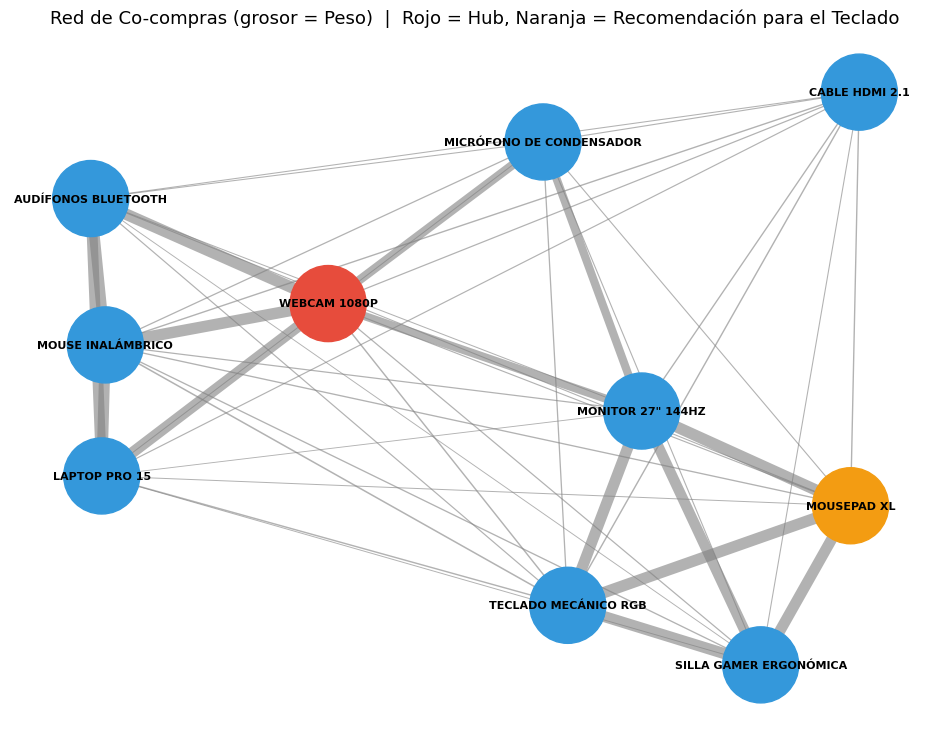

In [10]:
# 3. Renderizado: grosor de línea proporcional al peso
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G, weight="peso", seed=42, k=1.5)

pesos = [d["peso"] for _, _, d in G.edges(data=True)]
max_peso = max(pesos)
anchos = [0.3 + 8 * p / max_peso for p in pesos]

colores_nodos = ["#E74C3C" if n == hub else "#F39C12" if n == recomendacion else "#3498DB" for n in G.nodes()]

nx.draw_networkx_edges(G, pos, width=anchos, edge_color="gray", alpha=0.6)
nx.draw_networkx_nodes(G, pos, node_color=colores_nodos, node_size=3000)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold", font_color="black")

plt.title("Red de Co-compras (grosor = Peso)  |  Rojo = Hub, Naranja = Recomendación para el Teclado", fontsize=13)
plt.axis("off")
plt.show()

## 📋 Veredicto para el Director de Ventas

**1. Producto Ancla (Hub): `WEBCAM 1080P`**

La *Degree Centrality* da **1.0 a los 10 productos**: el grafo es **completo** (45 aristas = 10·9/2), porque cada producto se compró al menos una vez con todos los demás. Así, la métrica sin pesos no distingue a nadie. Para desempatar usamos el **grado ponderado** (total de co-compras):

| Producto | Co-compras |
|---|---|
| **WEBCAM 1080P** | **1,721** |
| MONITOR 27" 144HZ | 1,648 |
| TECLADO MECÁNICO RGB | 1,252 |
| MOUSE INALÁMBRICO | 1,226 |

La Webcam es el puente entre dos grupos: el de *home office* (Laptop, Mouse, Audífonos) y el de *streaming* (Micrófono, Monitor). Por eso es la que más compras adicionales arrastra y la que debe ir en la portada.

**2. Recomendación para `TECLADO MECÁNICO RGB`: `MOUSEPAD XL`** (359 co-compras)

Le siguen muy de cerca Silla Gamer (351) y Monitor (350), que forman el *setup gamer*. El resto de los productos no pasa de 37 co-compras con el teclado, así que esas conexiones son casi ruido.

**3. Visualización**

En el grafo se ven **tres paquetes** de aristas gruesas (gamer, home office y streaming). El resto de las líneas son delgadas, lo que confirma que el peso, y no la mera existencia de la arista, es lo que debe guiar al recomendador.